# Taylor Rule Duration Strategy
**Do deviations from the Taylor rule predict US Treasury yields?**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gabsmm18/taylor-rule-duration-strategy/blob/main/notebooks/taylor_rule_duration.ipynb)

Mattia Mariani, MSc Applied Economics and Finance, Copenhagen Business School

---

**Research question.** The Taylor rule provides a simple benchmark for the policy rate implied by inflation and labour-market slack. When the federal funds rate, or the path priced into short-term Treasury yields, deviates substantially from this benchmark, do yields subsequently move to close the gap? If so, the deviation can be traded through a duration position.

**Outline**
1. Theory and literature
2. Data
3. The Taylor rule and the trading signals
4. Treasury returns from yields
5. Predictive regressions
6. Backtest
7. Calendar-year performance and episodes
8. Robustness
9. Current signal
10. Limitations

*Research and educational project. Not investment advice.*

**To run:** store a free FRED API key as a Colab secret named `FRED_API_KEY` (key icon in the left sidebar), then `Runtime → Run all`.

## 1. Theory and literature

### 1.1 The Taylor rule
Taylor (1993) showed that US monetary policy in the late 1980s and early 1990s was well described by
$$ i^{T}_t = r^* + \pi_t + 0.5\,(\pi_t - \pi^*) + 0.5\,\tilde{y}_t $$
where $r^*$ is the neutral real rate, $\pi_t$ inflation, $\pi^*$ the inflation target (2%) and $\tilde{y}_t$ the output gap. Clarida, Galí & Gertler (2000) show that the inflation coefficient exceeding one (the *Taylor principle*) is what distinguishes the stabilising post-1979 Fed from the pre-Volcker era.

Here inflation is measured by **core PCE**, the Fed's preferred gauge, and the output gap is proxied through **Okun's law** as $\tilde{y}_t = 2\,(u^*_t - u_t)$, using the CBO estimate of the natural rate of unemployment $u^*$. The *balanced-approach* variant doubles the weight on the gap (0.5 → 1.0).

### 1.2 Why deviations could predict yields
Under the expectations hypothesis, the 2-year yield equals the average expected policy rate over the next two years plus a term premium:
$$ y^{(2)}_t \approx \frac{1}{2}\sum_{j} E_t[i_{t+j}] + TP_t $$
If the central bank eventually returns towards a Taylor-type reaction function, a policy rate far below the rule implies future hikes. A market that under-prices this convergence leaves 2-year yields "too low", and they should subsequently rise. Two signals follow:

- **Policy gap** $= i^{FF}_t - i^T_t$: is the Fed tighter (> 0) or looser (< 0) than the rule?
- **Market gap** $= y^{(2)}_t - i^T_t$: is the market pricing a path above (> 0) or below (< 0) the rule?

A positive gap suggests rates are high relative to fundamentals: expect yields to fall and go **long duration**. A negative gap suggests the opposite: go **short duration**.

### 1.3 Related evidence
Bond excess returns are predictable: by forward rates (Fama & Bliss, 1987; Cochrane & Piazzesi, 2005) and by macroeconomic factors (Ludvigson & Ng, 2009). The Taylor-rule gap is a parsimonious, economically motivated macro predictor. Orphanides (2001) warns that rules evaluated with revised data can look very different from those based on the information available in real time, a caveat discussed in Section 10.

## 2. Data

All series are from FRED, retrieved through the official API.

| Series | FRED code | Frequency | Publication lag applied |
|---|---|---|---|
| Core PCE price index | `PCEPILFE` | Monthly | 1 month |
| Unemployment rate | `UNRATE` | Monthly | 1 month |
| Natural rate of unemployment (CBO) | `NROU` | Quarterly | none (see limitations) |
| Effective federal funds rate | `FEDFUNDS` | Monthly average | none |
| 2-year and 10-year Treasury yields | `DGS2`, `DGS10` | Daily → month-end | none |
| 3-month Treasury bill | `DTB3` | Daily → month-end | none |

Core PCE and unemployment for month *m* are only published during month *m+1*. They are therefore shifted forward by one month, so that each signal uses only data available at the time. The sample starts in January 1987, the beginning of the Greenspan era.

In [1]:
import io
import json
import os
import time
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.figsize': (12, 5), 'axes.grid': True, 'grid.alpha': 0.3})
pd.set_option('display.float_format', '{:.3f}'.format)

In [2]:
SERIES = {
    "core_pce": "PCEPILFE",   # Core PCE price index, monthly (Fed's preferred inflation gauge)
    "unrate":   "UNRATE",     # Unemployment rate, monthly
    "nrou":     "NROU",       # CBO noncyclical rate of unemployment, quarterly
    "fedfunds": "FEDFUNDS",   # Effective federal funds rate, monthly average
    "y2":       "DGS2",       # 2-year Treasury constant-maturity yield, daily
    "y10":      "DGS10",      # 10-year Treasury constant-maturity yield, daily
    "tbill":    "DTB3",       # 3-month Treasury bill rate, daily (funding rate)
}

# Publication lag in months: value for month m is known at the end of month m + lag
PUB_LAG = {"core_pce": 1, "unrate": 1}

FRED_CSV_URL = "https://fred.stlouisfed.org/graph/fredgraph.csv?id={}"
FRED_API_URL = ("https://api.stlouisfed.org/fred/series/observations"
                "?series_id={}&api_key={}&file_type=json")
FRED_API_KEY = os.environ.get("FRED_API_KEY", "")


def _http_get(url: str, timeout: int = 60) -> str:
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=timeout) as resp:
        return resp.read().decode("utf-8")


def fetch_fred(series_id: str, retries: int = 3) -> pd.Series:
    """Download one FRED series (official API if FRED_API_KEY is set, else keyless CSV)."""
    last_err = None
    for attempt in range(retries):
        try:
            if FRED_API_KEY:
                obs = json.loads(_http_get(FRED_API_URL.format(series_id, FRED_API_KEY)))["observations"]
                s = pd.Series({pd.Timestamp(o["date"]): o["value"] for o in obs})
            else:
                df = pd.read_csv(io.StringIO(_http_get(FRED_CSV_URL.format(series_id))),
                                 index_col=0, parse_dates=True)
                s = df.iloc[:, 0]
            s = pd.to_numeric(s.replace(".", np.nan), errors="coerce").dropna().sort_index()
            s.name = series_id
            return s
        except Exception as e:
            last_err = e
            time.sleep(2 * (attempt + 1))
    raise RuntimeError(f"{series_id}: {last_err}")


def _monthly(s: pd.Series, how: str = "last") -> pd.Series:
    g = s.groupby(s.index.to_period("M"))
    return g.last() if how == "last" else g.mean()


def load_data(fetch=fetch_fred, start: str = "1987-01", drop_incomplete_month: bool = True,
              verbose: bool = True) -> pd.DataFrame:
    """
    Monthly DataFrame with:
      core_pce_yoy, unrate, nrou (lagged for publication), fedfunds, y2, y10, tbill (month-end).
    """
    raw = {k: fetch(sid) for k, sid in SERIES.items()}

    df = pd.DataFrame({
        "core_pce_yoy": _monthly(raw["core_pce"]).pct_change(12) * 100,
        "unrate": _monthly(raw["unrate"]),
        "fedfunds": _monthly(raw["fedfunds"]),
        "y2": _monthly(raw["y2"]),
        "y10": _monthly(raw["y10"]),
        "tbill": _monthly(raw["tbill"]),
    })
    # quarterly NROU -> monthly, forward-filled within the quarter
    nrou = raw["nrou"].copy()
    nrou.index = nrou.index.to_period("M")
    df["nrou"] = nrou.reindex(df.index.union(nrou.index)).ffill().reindex(df.index)

    if verbose:
        print("Last available observation per series:")
        print(df.apply(lambda c: c.last_valid_index()).to_string())

    # publication lags: inflation and unemployment of month m are known only at end of m+1
    for col, src in [("core_pce_yoy", "core_pce"), ("unrate", "unrate")]:
        df[col] = df[col].shift(PUB_LAG[src])

    if drop_incomplete_month:
        df = df.loc[df.index < pd.Timestamp.today().to_period("M")]
    # carry the latest macro print forward for up to 2 months at the end of the sample
    df[["core_pce_yoy", "unrate", "nrou"]] = df[["core_pce_yoy", "unrate", "nrou"]].ffill(limit=2)
    return df.loc[df.index >= pd.Period(start, "M")].dropna(subset=["y2", "fedfunds"])

In [3]:
try:
    from google.colab import userdata          # Colab Secrets
    FRED_API_KEY = userdata.get('FRED_API_KEY') or ''
except Exception:
    pass
if not FRED_API_KEY:
    from getpass import getpass
    FRED_API_KEY = getpass("Paste your FRED API key: ").strip()
print("Using FRED API" if FRED_API_KEY else "No key: using keyless CSV (may time out on Colab)")

Paste your FRED API key: ··········
Using FRED API


In [4]:
START = "1987-01"
df = load_data(fetch=fetch_fred, start=START)
print(f"\nSample: {df.index[0]} → {df.index[-1]}  ({len(df)} months)")
df.tail()

Last available observation per series:
core_pce_yoy    2026-09
unrate          2026-10
fedfunds        2026-10
y2              2026-11
y10             2026-11
tbill           2026-11
nrou            2026-11

Sample: 1987-01 → 2026-10  (478 months)


,core_pce_yoy,unrate,fedfunds,y2,y10,tbill,nrou
2026-06,3.162,4.300,3.630,4.140,4.440,3.740,4.396
2026-07,3.041,4.200,3.630,4.280,4.750,3.690,4.392
2026-08,2.995,4.100,3.630,4.340,4.750,3.780,4.392
2026-09,3.034,4.100,3.750,4.880,5.290,4.030,4.392
2026-10,3.121,4.200,3.880,4.560,4.940,3.990,4.388


## 3. The Taylor rule and the trading signals

In [5]:
def taylor_rate(df: pd.DataFrame, r_star: float = 2.0, pi_star: float = 2.0,
                a_pi: float = 0.5, a_gap: float = 0.5, okun: float = 2.0) -> pd.Series:
    """
    Taylor (1993):  i = r* + pi + a_pi (pi - pi*) + a_gap * output_gap
    Output gap proxied through Okun's law:  gap = okun * (u* - u)
    a_gap = 0.5 is the original rule; a_gap = 1.0 is the 'balanced-approach' rule.
    """
    pi = df["core_pce_yoy"]
    gap = okun * (df["nrou"] - df["unrate"])
    return r_star + pi + a_pi * (pi - pi_star) + a_gap * gap


def signals(df: pd.DataFrame, taylor: pd.Series, tenor: str = "y2") -> pd.DataFrame:
    """
    policy_gap = fed funds - Taylor rate   (>0: Fed tighter than the rule)
    market_gap = Treasury yield - Taylor rate (>0: market prices a path above the rule)
    Positive gap -> rates 'too high' relative to fundamentals -> expect yields to fall -> LONG duration.
    """
    return pd.DataFrame({
        "policy_gap": df["fedfunds"] - taylor,
        "market_gap": df[tenor] - taylor,
    })

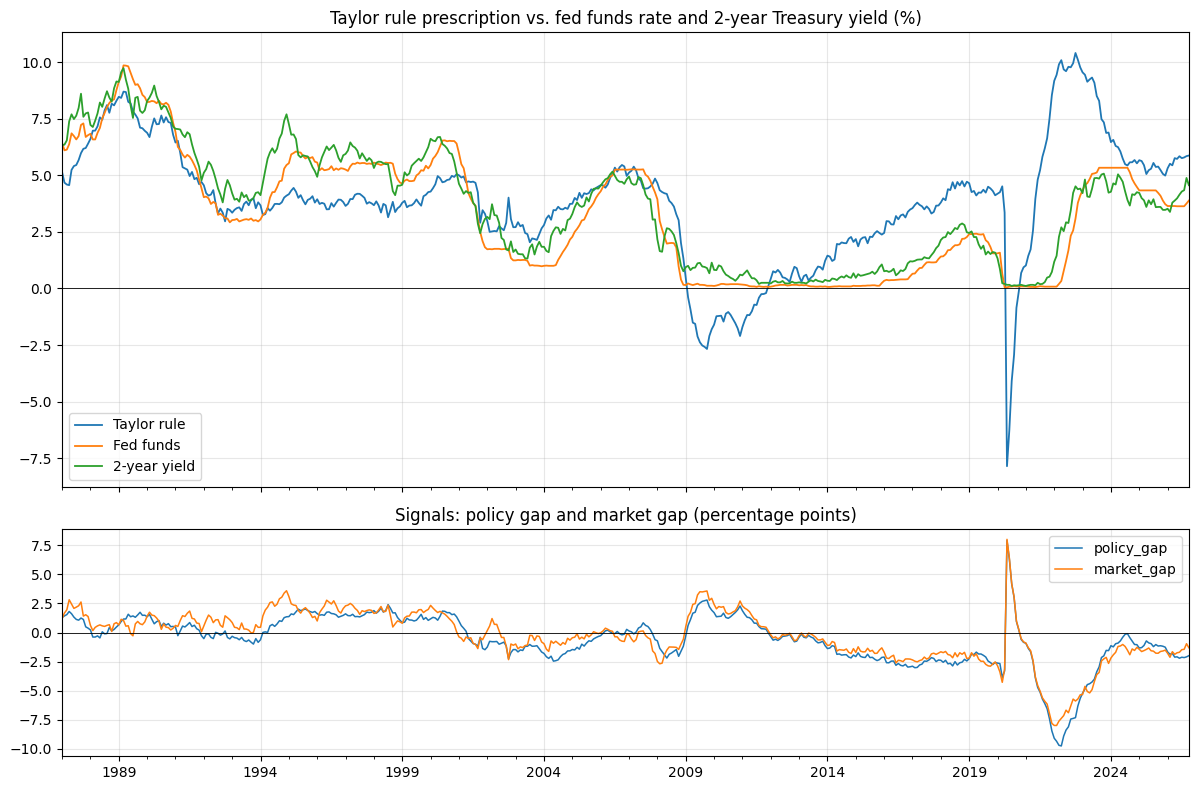

In [6]:
tr = taylor_rate(df)                     # baseline: r* = 2, Taylor (1993) coefficients
sig = signals(df, tr, tenor="y2")

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
pd.DataFrame({'Taylor rule': tr, 'Fed funds': df['fedfunds'], '2-year yield': df['y2']}).to_timestamp().plot(ax=axes[0], lw=1.3)
axes[0].set_title("Taylor rule prescription vs. fed funds rate and 2-year Treasury yield (%)")
axes[0].axhline(0, color='k', lw=0.6)
sig.to_timestamp().plot(ax=axes[1], lw=1.1)
axes[1].axhline(0, color='k', lw=0.6)
axes[1].set_title("Signals: policy gap and market gap (percentage points)")
plt.tight_layout(); plt.show()

The chart is the core of the project. Periods in which the fed funds rate sits well below the rule (2003–2004, 2021) preceded hiking cycles. Periods well above it (2008–2009) preceded easing or extended accommodation. Section 5 tests whether this relationship is statistically reliable.

## 4. Treasury returns from yields

FRED provides yields, not bond returns. Monthly returns are reconstructed by treating the constant-maturity Treasury as a par bond bought at month-end *t* (coupon equal to the yield) and revalued one month later at the new yield:
$$ R_{t+1} = P(c = y_t,\; y = y_{t+1}) - 1 + \frac{y_t}{12}, \qquad xr_{t+1} = R_{t+1} - \frac{y^{3m}_t}{12} $$
The excess return $xr$ is the return over financing at the 3-month T-bill rate, which is equivalent to the return on a Treasury futures position. The price change embeds duration and convexity exactly. The one-month ageing of the bond (roll-down) is ignored.

In [7]:
def par_bond_price(coupon: np.ndarray, yld: np.ndarray, maturity: float) -> np.ndarray:
    """Price (per 1 of face) of a semi-annual bond; yields and coupon in decimals."""
    c, y = np.asarray(coupon, float), np.asarray(yld, float)
    n = 2 * maturity
    h = y / 2
    small = np.abs(h) < 1e-10
    h_safe = np.where(small, 1e-10, h)
    disc = (1 + h_safe) ** (-n)
    annuity = np.where(small, n, (1 - disc) / h_safe)
    return c / 2 * annuity + disc


def bond_excess_returns(df: pd.DataFrame, tenor: str = "y2", maturity: float = 2.0) -> pd.DataFrame:
    """
    Monthly return of a constant-maturity Treasury, approximated as a par bond bought at
    end of month t (coupon = yield_t) and revalued at end of month t+1 at yield_{t+1}:
        R_{t+1} = P(c = y_t, y = y_{t+1}) - 1 + y_t / 12
    Excess return = R_{t+1} - tbill_t / 12   (funding at the 3-month T-bill rate).
    The one-month ageing of the bond (roll-down) is ignored.
    """
    y = df[tenor] / 100
    y_prev = y.shift(1)
    price = pd.Series(par_bond_price(y_prev.values, y.values, maturity), index=df.index)
    total = price - 1 + y_prev / 12
    excess = total - df["tbill"].shift(1) / 100 / 12
    dy = (y - y_prev) * 100
    return pd.DataFrame({"total": total, "excess": excess, "dy_pp": dy})

Performance statistics and the predictive-regression helper used in the rest of the notebook:

In [8]:
def perf_stats(r: pd.Series) -> pd.Series:
    r = r.dropna()
    r = r[r.ne(0).cummax()]
    cum = r.cumsum()
    dd = cum - cum.cummax()
    ann_ret, ann_vol = r.mean() * 12, r.std() * np.sqrt(12)
    return pd.Series({
        "Ann. return": ann_ret,
        "Ann. vol": ann_vol,
        "Sharpe": ann_ret / ann_vol if ann_vol > 0 else np.nan,
        "t-stat": (ann_ret / ann_vol) * np.sqrt(len(r) / 12) if ann_vol > 0 else np.nan,
        "Max drawdown": dd.min(),
        "Skewness": r.skew(),
        "Worst month": r.min(),
        "Hit rate": (r > 0).mean(),
        "Months": len(r),
    })


def drawdown(r: pd.Series) -> pd.Series:
    cum = r.fillna(0).cumsum()
    return cum - cum.cummax()


def predictive_regression(signal: pd.Series, yields: pd.Series, horizon: int = 12):
    """
    Regress the change in yield over the next `horizon` months on today's signal:
        y_{t+h} - y_t = a + b * signal_t + e
    Overlapping observations -> Newey-West (HAC) standard errors with `horizon` lags.
    A NEGATIVE b means: when rates sit above the Taylor benchmark, they subsequently fall.
    """
    import statsmodels.api as sm
    dy = yields.shift(-horizon) - yields
    data = pd.concat([dy.rename("dy"), signal.rename("signal")], axis=1).dropna()
    X = sm.add_constant(data["signal"])
    res = sm.OLS(data["dy"], X).fit(cov_type="HAC", cov_kwds={"maxlags": horizon})
    return pd.Series({"beta": res.params["signal"], "t-stat (NW)": res.tvalues["signal"],
                      "R2": res.rsquared, "N": int(res.nobs)})

In [9]:
ret2 = bond_excess_returns(df, "y2", 2.0)
ret10 = bond_excess_returns(df, "y10", 10.0)
check = pd.DataFrame({'2-year': perf_stats(ret2['excess']), '10-year': perf_stats(ret10['excess'])})
print("Buy-and-hold Treasury excess returns (sanity check: positive term premium, 10y riskier than 2y)")
display(check.loc[['Ann. return', 'Ann. vol', 'Sharpe', 'Max drawdown']])

Buy-and-hold Treasury excess returns (sanity check: positive term premium, 10y riskier than 2y)


,2-year,10-year
Ann. return,0.007,0.021
Ann. vol,0.018,0.074
Sharpe,0.364,0.284
Max drawdown,-0.092,-0.384


## 5. Predictive regressions

Before trading, we test the economic hypothesis directly:
$$ y_{t+h} - y_t = \alpha + \beta \cdot \text{gap}_t + \varepsilon_{t+h} $$
A **negative** $\beta$ means that when rates sit above the Taylor benchmark they subsequently fall, and vice versa. Because the 6- and 12-month changes overlap from one month to the next, standard errors use Newey-West (HAC) corrections with $h$ lags. As a rule of thumb, |t| > 2 indicates significance at the 5% level.

In [10]:
rows = {}
for tenor, label in [("y2", "2-year"), ("y10", "10-year")]:
    s = signals(df, tr, tenor)
    for name in ["policy_gap", "market_gap"]:
        for h in [6, 12]:
            rows[(label, name, f"{h}m")] = predictive_regression(s[name], df[tenor], h)
reg = pd.DataFrame(rows).T
reg.index.names = ["Yield", "Signal", "Horizon"]
display(reg.round(3))

beta  t-stat (NW)    R2       N
Yield   Signal     Horizon                                  
2-year  policy_gap 6m      -0.125       -3.481 0.112 472.000
                   12m     -0.223       -3.245 0.150 466.000
        market_gap 6m      -0.105       -2.637 0.079 472.000
                   12m     -0.182       -2.318 0.100 466.000
10-year policy_gap 6m      -0.063       -2.185 0.043 472.000
                   12m     -0.127       -2.779 0.100 466.000
        market_gap 6m      -0.061       -2.468 0.053 472.000
                   12m     -0.114       -2.794 0.106 466.000

## 6. Backtest

**Positions.** The position is proportional to the gap and capped at ±1: a gap of 2 percentage points or more means a full long or short position, i.e. 1 unit of notional in the 2-year Treasury. Positions are set at month-end *t* and earn the excess return of month *t+1*.

**Benchmark.** A permanent long position in the 2-year Treasury, which earns the term premium. A timing strategy must be judged against this, since a strategy that is mostly long would look good simply because yields fell from 1987 to 2021.

**Costs.** 1 basis point of notional per unit of position change, conservative for on-the-run Treasuries or futures.

In [11]:
def position_scaled(signal: pd.Series, scale: float = 2.0) -> pd.Series:
    """Continuous position in [-1, 1]: a 2pp gap (default) -> full long/short."""
    return (signal / scale).clip(-1, 1)


def position_sign(signal: pd.Series, band: float = 0.0) -> pd.Series:
    """+1 / -1 outside a +-band (pp), 0 inside it."""
    pos = np.sign(signal).where(signal.abs() > band, 0.0)
    return pos.where(signal.notna())


def backtest(position: pd.Series, excess: pd.Series, cost_bp: float = 1.0) -> pd.DataFrame:
    """
    position at end of month t applied to excess return of month t+1.
    cost_bp: cost in basis points of notional per unit of position change.
    """
    w = position.reindex(excess.index).fillna(0.0)
    w_lag = w.shift(1).fillna(0.0)
    gross = w_lag * excess.fillna(0.0)
    turnover = (w - w.shift(1).fillna(0.0)).abs().shift(1).fillna(0.0)
    cost = turnover * cost_bp / 10_000
    return pd.DataFrame({"gross": gross, "cost": cost, "net": gross - cost,
                         "position": w_lag, "turnover": turnover})

In [12]:
def run_all(df: pd.DataFrame, tenor: str = "y2", maturity: float = 2.0, r_star: float = 2.0,
            a_gap: float = 0.5, scale: float = 2.0, cost_bp: float = 1.0) -> dict:
    tr = taylor_rate(df, r_star=r_star, a_gap=a_gap)
    sig = signals(df, tr, tenor)
    rets = bond_excess_returns(df, tenor, maturity)
    pos = {
        "Long duration (benchmark)": pd.Series(1.0, index=df.index),
        "Policy gap": position_scaled(sig["policy_gap"], scale),
        "Market gap": position_scaled(sig["market_gap"], scale),
    }
    res = {k: backtest(p, rets["excess"], cost_bp) for k, p in pos.items()}
    return {"taylor": tr, "signals": sig, "returns": rets, "positions": pos, "results": res}


def current_signal(df: pd.DataFrame, **kw) -> pd.Series:
    out = run_all(df, **kw)
    t = df.index[-1]
    return pd.Series({
        "as_of": str(t),
        "fed_funds_%": df.loc[t, "fedfunds"],
        "taylor_rate_%": out["taylor"].loc[t],
        "2y_yield_%": df.loc[t, "y2"],
        "policy_gap_pp": out["signals"].loc[t, "policy_gap"],
        "market_gap_pp": out["signals"].loc[t, "market_gap"],
        "position_policy_gap": out["positions"]["Policy gap"].loc[t],
        "position_market_gap": out["positions"]["Market gap"].loc[t],
    })

In [13]:
COST_BP = 1.0
base2 = run_all(df, tenor="y2", maturity=2.0, cost_bp=COST_BP)
base10 = run_all(df, tenor="y10", maturity=10.0, cost_bp=COST_BP)

print("=== 2-year Treasury (baseline) ===")
stats2 = pd.DataFrame({k: perf_stats(v['net']) for k, v in base2['results'].items()})
display(stats2)
print("\n=== 10-year Treasury ===")
stats10 = pd.DataFrame({k: perf_stats(v['net']) for k, v in base10['results'].items()})
display(stats10)

# correlation with the long-only benchmark: is the strategy just 'long bonds'?
nets = pd.DataFrame({k: v['net'] for k, v in base2['results'].items()})
print("\nCorrelation of monthly returns (2-year):")
display(nets.corr().round(2))
avg_pos = pd.DataFrame({k: v['position'] for k, v in base2['results'].items()}).mean()
print("\nAverage position (+1 = fully long):"); display(avg_pos.round(2).to_frame('avg position'))

=== 2-year Treasury (baseline) ===


,Long duration (benchmark),Policy gap,Market gap
Ann. return,0.007,0.004,0.005
Ann. vol,0.018,0.012,0.013
Sharpe,0.364,0.321,0.343
t-stat,2.296,2.021,2.165
Max drawdown,-0.092,-0.052,-0.051
Skewness,0.138,0.303,0.338
Worst month,-0.016,-0.014,-0.015
Hit rate,0.545,0.532,0.543
Months,477.000,477.000,477.000



=== 10-year Treasury ===


,Long duration (benchmark),Policy gap,Market gap
Ann. return,0.021,0.003,0.024
Ann. vol,0.074,0.054,0.059
Sharpe,0.284,0.053,0.409
t-stat,1.789,0.336,2.577
Max drawdown,-0.384,-0.436,-0.264
Skewness,0.062,-0.399,0.131
Worst month,-0.074,-0.096,-0.050
Hit rate,0.526,0.488,0.545
Months,477.000,477.000,477.000



Correlation of monthly returns (2-year):


,Long duration (benchmark),Policy gap,Market gap
Long duration (benchmark),1.000,-0.150,-0.030
Policy gap,-0.150,1.000,0.850
Market gap,-0.030,0.850,1.000



Average position (+1 = fully long):


,avg position
Long duration (benchmark),1.000
Policy gap,-0.160
Market gap,-0.040


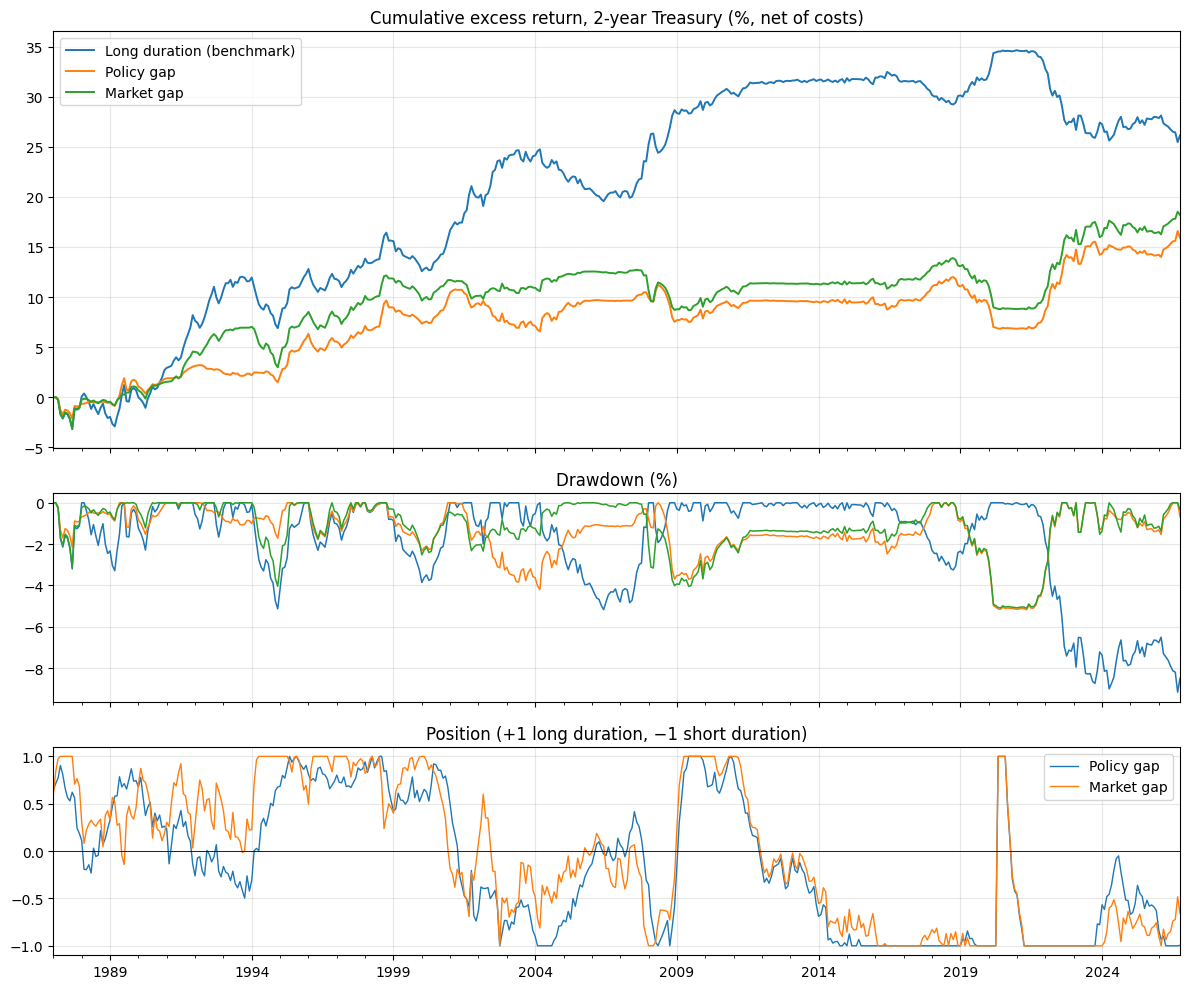

In [14]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True, gridspec_kw={'height_ratios': [2, 1, 1]})
for name, res in base2['results'].items():
    res['net'].cumsum().mul(100).to_timestamp().plot(ax=axes[0], label=name, lw=1.4)
    drawdown(res['net']).mul(100).to_timestamp().plot(ax=axes[1], label=name, lw=1.1)
axes[0].set_title("Cumulative excess return, 2-year Treasury (%, net of costs)"); axes[0].legend()
axes[1].set_title("Drawdown (%)")
pd.DataFrame({k: base2['positions'][k] for k in ['Policy gap', 'Market gap']}).to_timestamp().plot(ax=axes[2], lw=1)
axes[2].axhline(0, color='k', lw=0.6); axes[2].set_title("Position (+1 long duration, −1 short duration)")
plt.tight_layout(); plt.show()

## 7. Calendar-year performance and episodes

Duration strategies are judged by how they behave across rate cycles. Episodes of particular interest:
- **1994**: the "bond massacre", when the Fed doubled rates from 3% to 6% within a year.
- **2004–2006** and **2015–2018**: gradual hiking cycles.
- **2001**, **2008** and **2020**: aggressive easing.
- **2022**: the fastest hiking cycle since the early 1980s, after a year in which inflation far exceeded the policy rate.

In [15]:
yearly = pd.DataFrame({k: v['net'] for k, v in base2['results'].items()})
yearly = yearly.groupby(yearly.index.year).sum() * 100
yearly['Market gap − benchmark'] = yearly['Market gap'] - yearly['Long duration (benchmark)']
print("Calendar-year excess returns, 2-year Treasury (%)")
display(yearly.round(2))
highlight = [y for y in [1994, 2001, 2004, 2008, 2013, 2018, 2020, 2022, 2023, 2024] if y in yearly.index]
print("\nSelected episodes:"); display(yearly.loc[highlight].round(2))

Calendar-year excess returns, 2-year Treasury (%)


,Long duration (benchmark),Policy gap,Market gap,Market gap − benchmark
1987,-1.100,-0.890,-1.050,0.060
1988,-0.970,0.330,0.550,1.530
1989,2.790,2.150,1.500,-1.280
1990,1.990,0.220,0.480,-1.500
1991,5.500,1.220,3.050,-2.450
1992,1.730,-0.410,1.430,-0.310
1993,1.670,-0.290,0.970,-0.700
1994,-4.700,-0.850,-3.960,0.740
1995,5.420,4.390,5.200,-0.220
1996,-0.490,-0.310,-0.040,0.460



Selected episodes:


,Long duration (benchmark),Policy gap,Market gap,Market gap − benchmark
1994,-4.700,-0.850,-3.960,0.740
2001,4.170,-0.530,-1.570,-5.740
2004,-1.390,1.360,1.080,2.470
2008,5.110,-2.950,-3.470,-8.580
2013,-0.020,-0.030,-0.010,0.010
2018,-0.550,0.550,0.520,1.070
2020,2.870,-2.790,-2.790,-5.660
2022,-6.130,6.130,6.130,12.260
2023,-0.040,0.250,0.040,0.080
2024,-0.660,0.840,1.380,2.040


## 8. Robustness

The baseline uses $r^* = 2\%$ (Taylor's original assumption) and a gap coefficient of 0.5. Estimates of the neutral rate fell markedly after 2008, and the Fed's own communications have referenced the balanced-approach rule. The grid below varies both, for both tenors.

As in any backtest, this table is a check that conclusions do not hinge on one specification. It is not a search for the best parameters.

In [16]:
grid = {}
for tenor, mat in [("y2", 2.0), ("y10", 10.0)]:
    for r_star in [0.5, 1.0, 2.0]:
        for a_gap in [0.5, 1.0]:
            res = run_all(df, tenor=tenor, maturity=mat, r_star=r_star, a_gap=a_gap, cost_bp=COST_BP)['results']
            grid[(tenor, r_star, a_gap)] = {k: perf_stats(v['net'])['Sharpe'] for k, v in res.items()}
g = pd.DataFrame(grid).T
g.index.names = ['Tenor', 'r*', 'gap coef.']
display(g.round(2))

Long duration (benchmark)  Policy gap  Market gap
Tenor r*    gap coef.                                                   
y2    0.500 0.500                          0.360       0.600       0.590
            1.000                          0.360       0.590       0.530
      1.000 0.500                          0.360       0.540       0.550
            1.000                          0.360       0.550       0.490
      2.000 0.500                          0.360       0.320       0.340
            1.000                          0.360       0.390       0.350
y10   0.500 0.500                          0.280       0.330       0.440
            1.000                          0.280       0.340       0.390
      1.000 0.500                          0.280       0.250       0.430
            1.000                          0.280       0.290       0.370
      2.000 0.500                          0.280       0.050       0.410
            1.000                          0.280       0.140       0.340

In [17]:
periods = {"1987–1999": ("1987-01", "1999-12"), "2000–2008": ("2000-01", "2008-12"),
           "2009–2015 (zero lower bound)": ("2009-01", "2015-12"), "2016–today": ("2016-01", str(df.index[-1]))}
sub = {}
for lbl, (a, b) in periods.items():
    for k, v in base2['results'].items():
        sub[(lbl, k)] = perf_stats(v['net'].loc[a:b])[['Ann. return', 'Sharpe', 'Max drawdown']]
print("Sub-period performance, 2-year Treasury")
display(pd.DataFrame(sub).T.round(3))

Sub-period performance, 2-year Treasury


Ann. return  Sharpe  \
1987–1999                    Long duration (benchmark)        0.010   0.484   
                             Policy gap                       0.006   0.477   
                             Market gap                       0.008   0.536   
2000–2008                    Long duration (benchmark)        0.017   0.848   
                             Policy gap                      -0.000  -0.011   
                             Market gap                      -0.002  -0.140   
2009–2015 (zero lower bound) Long duration (benchmark)        0.004   0.453   
                             Policy gap                       0.004   0.511   
                             Market gap                       0.004   0.624   
2016–today                   Long duration (benchmark)       -0.005  -0.287   
                             Policy gap                       0.005   0.369   
                             Market gap                       0.006   0.382   

                                                        Max drawdown  
1987–1999                    Long duration (benchmark)        -0.051  
                             Policy gap                       -0.021  
                             Market gap                       -0.040  
2000–2008                    Long duration (benchmark)        -0.052  
                             Policy gap                       -0.042  
                             Market gap                       -0.040  
2009–2015 (zero lower bound) Long duration (benchmark)        -0.009  
                             Policy gap                       -0.009  
                             Market gap                       -0.009  
2016–today                   Long duration (benchmark)        -0.092  
                             Policy gap                       -0.052  
                             Market gap                       -0.051

## 9. Current signal
Based on the latest complete month. A positive position means long duration (the model expects 2-year yields to fall); a negative position means short duration.

In [18]:
display(current_signal(df).to_frame('value'))

,value
as_of,2026-10
fed_funds_%,3.880
taylor_rate_%,5.870
2y_yield_%,4.560
policy_gap_pp,-1.990
market_gap_pp,-1.310
position_policy_gap,-0.995
position_market_gap,-0.655


## 10. Limitations

1. **Revised data.** Core PCE and especially the CBO natural rate of unemployment are revised over time. Publication lags are applied, but the values used are today's vintages rather than those available in real time (Orphanides, 2001). A real-time version would use ALFRED vintages.
2. **The neutral rate is unobserved.** $r^*$ is treated as constant, while estimates such as Laubach & Williams (2003) declined substantially after 2008. The robustness grid only partially addresses this.
3. **Zero lower bound.** Between 2009 and 2015, and in 2020–2021, the policy rate was constrained at zero and policy operated through asset purchases and forward guidance, which the rule does not capture.
4. **Return approximation.** Constant-maturity yields approximate traded bonds, and roll-down is ignored.
5. **A benchmark, not the Fed's reaction function.** The Fed does not follow the Taylor rule mechanically. The project tests whether deviations from a simple benchmark carry information, not whether the Fed "should" follow it.
6. **No formal test of performance differences** relative to the benchmark.

## References
- Clarida, R., Galí, J. & Gertler, M. (2000). Monetary policy rules and macroeconomic stability: Evidence and some theory. *Quarterly Journal of Economics*.
- Cochrane, J. & Piazzesi, M. (2005). Bond risk premia. *American Economic Review*.
- Fama, E. & Bliss, R. (1987). The information in long-maturity forward rates. *American Economic Review*.
- Laubach, T. & Williams, J. (2003). Measuring the natural rate of interest. *Review of Economics and Statistics*.
- Ludvigson, S. & Ng, S. (2009). Macro factors in bond risk premia. *Review of Financial Studies*.
- Orphanides, A. (2001). Monetary policy rules based on real-time data. *American Economic Review*.
- Taylor, J. (1993). Discretion versus policy rules in practice. *Carnegie-Rochester Conference Series on Public Policy*.